In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,SimpleRNN,Dense,Dropout

In [2]:
from pathlib import Path
data_f = Path(r"D:\Downloads\Dataset\IMDB\IMDB Dataset.csv")
df = pd.read_csv(data_f)
print(df.head())
print(df.shape)
print(df.columns)

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
(50000, 2)
Index(['review', 'sentiment'], dtype='object')


In [3]:
print("Dataset information: ",df.info())
print("Missing values: ",df.isnull().sum())
print("Duplicates: ", df.duplicated().sum())
print(df['sentiment'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB
Dataset information:  None
Missing values:  review       0
sentiment    0
dtype: int64
Duplicates:  418
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [5]:
df = df.dropna(subset=['review','sentiment'])
df = df.drop_duplicates()
df['sentiment'] = df['sentiment'].map({
    'positive': 1,
    'negative': 0
})
print("Shape after cleaning: ",df.shape)
print("Missing values: ", df.isnull().sum())
print("Duplicates: ",df.duplicated().sum())
print(df.head())

Shape after cleaning:  (49582, 2)
Missing values:  review       0
sentiment    0
dtype: int64
Duplicates:  0
                                              review  sentiment
0  One of the other reviewers has mentioned that ...          1
1  A wonderful little production. <br /><br />The...          1
2  I thought this was a wonderful way to spend ti...          1
3  Basically there's a family where a little boy ...          0
4  Petter Mattei's "Love in the Time of Money" is...          1


In [7]:
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=10000)
tokenizer.fit_on_texts(df['review'])
x = tf.keras.preprocessing.sequence.pad_sequences(
    tokenizer.texts_to_sequences(df['review']),
    maxlen = 200
)
y = df['sentiment'].values
x_train,x_test = x[:40000],x[40000:]
y_train,y_test = y[:40000],y[40000:]
print("Training:", x_train.shape)
print("Testing:", x_test.shape)

Training: (40000, 200)
Testing: (9582, 200)


In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(10000,32),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1,activation='sigmoid')
])
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_2 (SimpleRNN)             │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(x_train,y_train,epochs=5,batch_size=64,validation_split=0.2)
loss, acc = model.evaluate(x_test,y_test,verbose=0)
print(loss)
print(acc*100)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.5667 - loss: 0.6686 - val_accuracy: 0.7984 - val_loss: 0.4463
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.8170 - loss: 0.4296 - val_accuracy: 0.8324 - val_loss: 0.3950
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.8838 - loss: 0.2993 - val_accuracy: 0.8316 - val_loss: 0.4071
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9294 - loss: 0.1933 - val_accuracy: 0.8328 - val_loss: 0.4512
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9596 - loss: 0.1197 - val_accuracy: 0.8089 - val_loss: 0.5651
0.5966854691505432
79.89981174468994


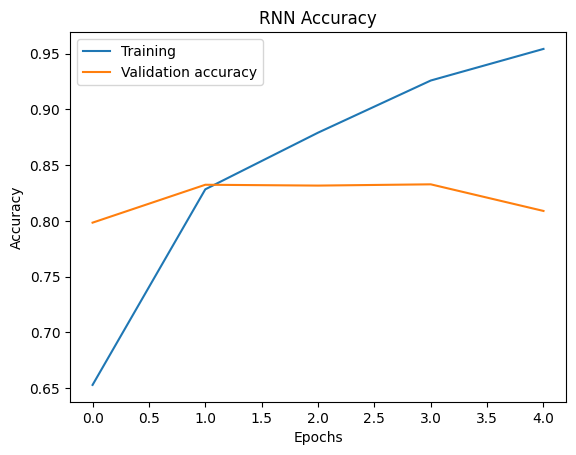

In [20]:
plt.plot(history.history['accuracy'],label="Training")
plt.plot(history.history['val_accuracy'], label = "Validation accuracy")
plt.title('RNN Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

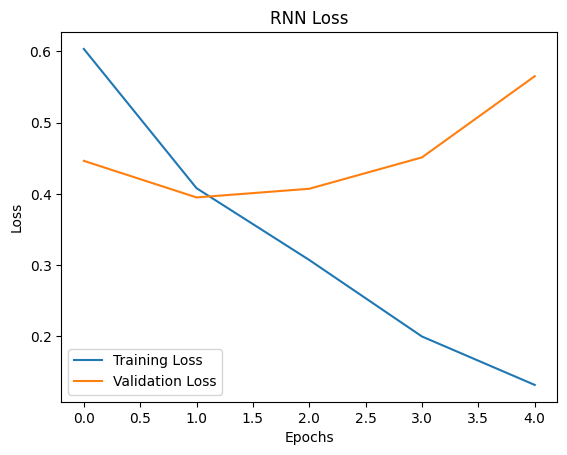

In [21]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('RNN Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [23]:
predictions = model.predict(x_test[:10])
for i in range(10):
    predicted = 'Positive' if predictions[i][0] >= 0.5 else 'Negative'
    actual = 'Positive' if y_test[i] == 1 else 'Negative'
    print("Predicted:", predicted)
    print("Actual:", actual)
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
Predicted: Positive
Actual: Positive

Predicted: Negative
Actual: Negative

Predicted: Negative
Actual: Positive

Predicted: Negative
Actual: Negative

Predicted: Negative
Actual: Negative

Predicted: Positive
Actual: Positive

Predicted: Positive
Actual: Positive

Predicted: Negative
Actual: Negative

Predicted: Positive
Actual: Positive

Predicted: Positive
Actual: Positive

